# Issues with Marginal-Based Classification, or, Figure 1

In [2]:
import numpy as np

np.random.seed(42)
SIGMA_X     = 1.0                       # width of the Gaussian tuning
PEAK_RATE   = 1.0                       # <- stays in arbitrary units
N_SAMPLES   = 10_000
CORR_LEVELS = [0.0, 0.5, 0.9]
Y_BINS      = 30
GRID_LIM    = 4.0


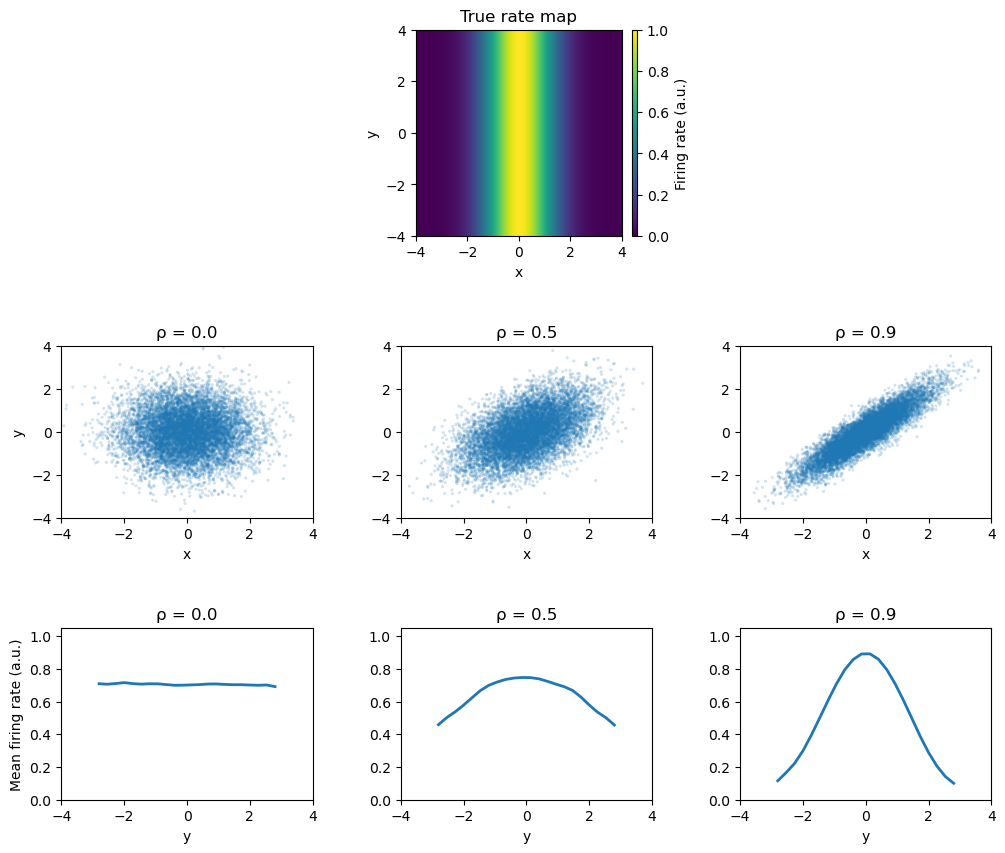

In [3]:
import matplotlib.pyplot as plt
from matplotlib import gridspec
from mpl_toolkits.axes_grid1 import make_axes_locatable
from scipy.ndimage import gaussian_filter1d

def firing_rate(x, y):
    return PEAK_RATE * np.exp(-0.5 * (x / SIGMA_X) ** 2)

fig = plt.figure(figsize=(12, 10))
gs = gridspec.GridSpec(
    nrows=3,
    ncols=3,
    height_ratios=[1.2, 1.0, 1.0],
    hspace=0.4,
    wspace=0.35,
)

gs.update(hspace=0.60)  

ROW_TITLES = ["", "Sampling schemes", "Apparent tuning curves"]  # row labels

# true rate map
ax_rate = fig.add_subplot(gs[0, :])
ax_rate.set_box_aspect(1)           

grid = np.linspace(-GRID_LIM, GRID_LIM, 200)
rate_map = firing_rate(*np.meshgrid(grid, grid))
im = ax_rate.imshow(
    rate_map,
    extent=[-GRID_LIM, GRID_LIM, -GRID_LIM, GRID_LIM],
    origin="lower",
    cmap="viridis",
    aspect="equal",
    vmin=0, vmax=PEAK_RATE,
)

divider = make_axes_locatable(ax_rate)
cax = divider.append_axes("right", size="2.5%", pad=0.1)
cbar = fig.colorbar(im, cax=cax)
cbar.set_label("Firing rate (a.u.)")

ax_rate.set_xlabel("x")
ax_rate.set_ylabel("y")
ax_rate.set_anchor('C')                
ax_rate.set_title("True rate map")

# sampling schemes
for idx, rho in enumerate(CORR_LEVELS):
    # draw samples
    cov        = [[1.0, rho], [rho, 1.0]]
    sx, sy     = np.random.multivariate_normal([0, 0], cov, size=N_SAMPLES).T
    fr         = firing_rate(sx, sy)

    # sampling scatter plot
    ax_samp = fig.add_subplot(gs[1, idx])
    ax_samp.scatter(sx, sy, s=5, alpha=0.2, edgecolor="none")
    ax_samp.set_xlim(-GRID_LIM, GRID_LIM)
    ax_samp.set_ylim(-GRID_LIM, GRID_LIM)
    ax_samp.set_xlabel("x")
    if idx == 0:
        ax_samp.set_ylabel("y")
    ax_samp.set_title(f"ρ = {rho:.1f}")

    # marginal tuning
    bin_edges = np.linspace(-GRID_LIM, GRID_LIM, Y_BINS + 1)
    y_idx     = np.digitize(sy, bin_edges) - 1
    y_idx     = np.clip(y_idx, 0, Y_BINS - 1)
    
    rate_sums = np.zeros(Y_BINS, dtype=float)   
    counts    = np.zeros(Y_BINS, dtype=int)
    np.add.at(rate_sums, y_idx, fr)
    np.add.at(counts,   y_idx, 1)

    # smooth out weird low-occupancy sampling 
    sigma = 1
    sm_sum    = gaussian_filter1d(rate_sums, sigma=sigma, mode="nearest")
    sm_counts = gaussian_filter1d(counts.astype(float), sigma=sigma, mode="nearest")
    
    with np.errstate(divide="ignore", invalid="ignore"):
        sm_rates = np.divide(sm_sum, sm_counts, where=sm_counts > 0)
    
    MIN_COUNT = 20
    sm_rates[sm_counts < MIN_COUNT] = np.nan

    # plot
    bin_centres = 0.5 * (bin_edges[:-1] + bin_edges[1:])
    ax_marg = fig.add_subplot(gs[2, idx])
    ax_marg.plot(bin_centres, sm_rates, lw=2)
    ax_marg.set_xlim(-GRID_LIM, GRID_LIM)
    ax_marg.set_ylim(0, PEAK_RATE * 1.05)
    ax_marg.set_xlabel("y")
    if idx == 0:
        ax_marg.set_ylabel("Mean firing rate (a.u.)")
    ax_marg.set_title(f"ρ = {rho:.1f}")


In [4]:
from pathlib import Path

proj_dir = Path().resolve().parent

plt.savefig(proj_dir / 'figs/fig1a.png', dpi=300)

<Figure size 640x480 with 0 Axes>